### Step 0

In [1]:
# CodeGrade step0

# Import Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris



### Step 1

In [2]:
# CodeGrade step0

# Load the Iris dataset
iris = load_iris()
data = pd.DataFrame(iris.data, columns=iris.feature_names)
data['target'] = iris.target



In [3]:
# Look at it
print(data.head())

# Check for missing values
print(data.isnull().sum())



   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


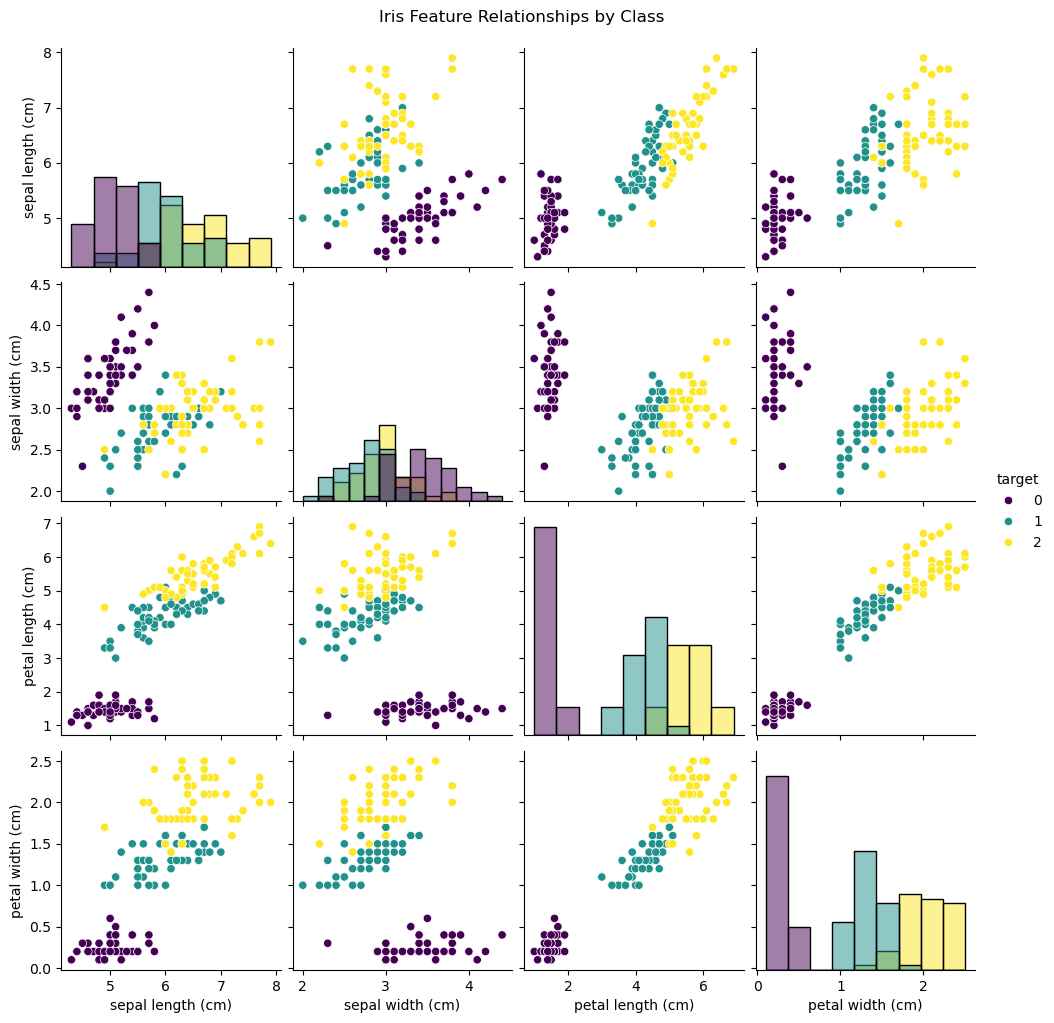

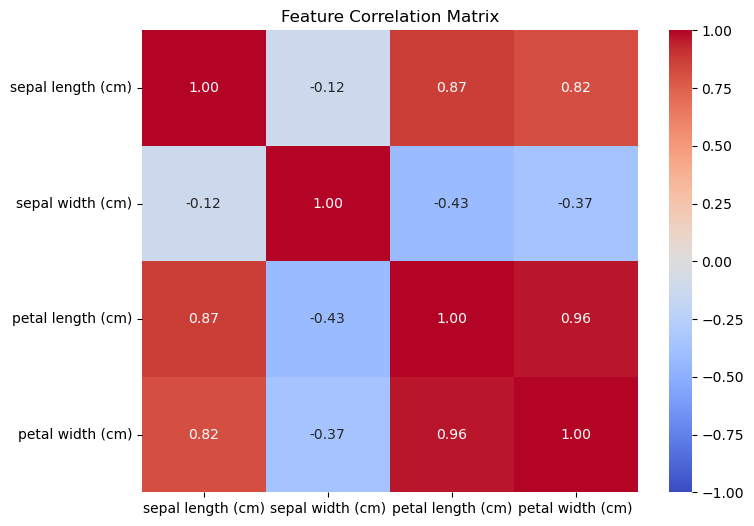

In [4]:
# Visualize relationships

# Pairplot: scatter plots for every feature pair, colored by species,
# with distributions on the diagonal
sns.pairplot(data, hue='target', palette='viridis', diag_kind='hist')
plt.suptitle('Iris Feature Relationships by Class', y=1.02)
plt.show()

# Correlation heatmap of the four numeric features
plt.figure(figsize=(8, 6))
sns.heatmap(
    data.drop(columns='target').corr(),
    annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1
)
plt.title('Feature Correlation Matrix')
plt.show()

In [16]:
# CodeGrade step1

# Encode target variable as categorical
data['target'] = data['target'].astype('category')

# Separate features and target variable
X = data.drop(columns=['target'])
y = data['target']

# Standardize numerical features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split the Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Shapes
shapes = (X_train.shape, X_test.shape, y_train.shape, y_test.shape)

### Step 2

In [17]:
# CodeGrade step0

# Train the SVM Model
# Initialize the SVM classifier with an RBF kernel
svc_model = SVC(kernel='rbf', probability=True)

# Train the model
svc_model.fit(X_train, y_train)

SVC(probability=True)

In [18]:
# CodeGrade step2

# Predict on the test data
y_pred = svc_model.predict(X_test)
y_pred_proba = svc_model.predict_proba(X_test)[:, 1]

### Step 3


In [19]:
# CodeGrade step3

# Classification report and confusion matrix
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=iris.target_names)

In [20]:
# Classification Report
print(cm)
print(report)

[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Step 4

In [22]:
# CodeGrade step0

# Optimize the Model
# Hyperparameter tuning with GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid_search = GridSearchCV(SVC(probability=True), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=SVC(probability=True),
             param_grid={'C': [0.1, 1, 10], 'gamma': [1, 0.1, 0.01, 0.001],
                         'kernel': ['rbf']},
             scoring='accuracy')

In [24]:
# CodeGrade step4

# Grid Search Best
best_params = grid_search.best_params_
best_score = grid_search.best_score_

### Step 5

In [13]:
# CodeGrade step0

# Train the optimized model
optimized_model = grid_search.best_estimator_
optimized_model.fit(X_train, y_train)

SVC(C=1, gamma=0.1, probability=True)

In [25]:
# CodeGrade step5

# Get predicted probabilities for the positive class (class 1)
y_pred_proba = optimized_model.predict_proba(X_test)[:, 1]

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba, pos_label=1)

# Calculate the AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

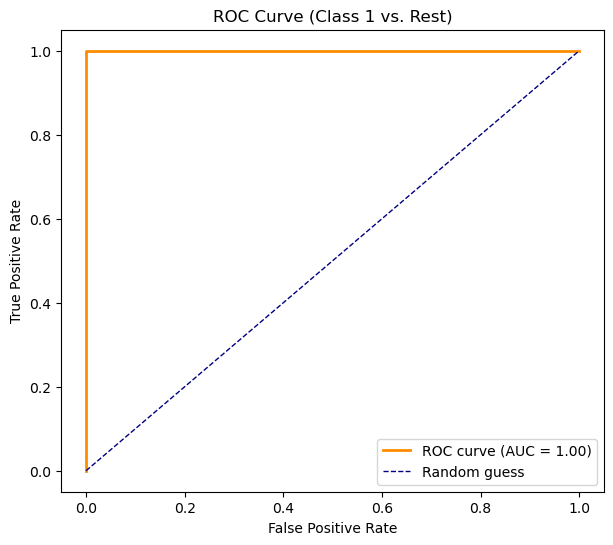

In [26]:
# Plot the ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Class 1 vs. Rest)')
plt.legend(loc='lower right')
plt.show()